# Solving Inverse Problem using Connectome Spectrum Electromagnetic Tomography (CSET)

In this section we will solve the inverse problem using our new method CSET. This requires the eeg measurements, the forward solution and the connectome spectrum transform (prior). <br>
The method solves the following problem: $$\vec{x}^* = \text{argmin}_{\vec{x}} \lVert A\vec{x}-b \rVert_2^2 + \lambda \lVert F\vec{x}\rVert_1$$
where
- $\vec{x}^* \in \mathbb{R}^n$ is the reconstructed brain activity.
- $\vec{x} \in \mathbb{R}^n$ is the brain activity.
- $\vec{b} \in \mathbb{R}^m$ are the eeg measurements.
- $A \in \mathbb{R}^{m\times n}$ is the forward matrix.
- $F \in \mathbb{R}^{n \times n}$ is the connectome spectrum transform.
- $\lambda \in \mathbb{R}$ is the regularizer parameter.

Regularizing with $\lVert F\vec{x} \rVert_1$ imposes the connectome spectrum of $\vec{x}$ to be sparse and $\lambda$ 

## Imports

In [34]:
#%matplotlib qt

import mindmap as mm
import mne
import numpy as np
from pathlib import Path

import pyxu.abc as pxa
import pyxu.operator as pxo 
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

## Data

In [35]:
sub     = "sub-pat10"

# configuration
config = mm.io.read_config("../configurations/spike.yml")
mm_dir = Path(config["MM_DIR"])
fs_dir = Path(config["FS_DIR"])

# files
forward = mm_dir/sub/"fwd"/f"{sub}_bem-fwd.fif"
cst     = mm_dir/sub/"cst"/f"{sub}_cst-template.npy"
eeg     = mm_dir/sub/"eeg"/f"{sub}_coreg_ave.fif"

# parameters
lam           = 0.00001
initial_guess = "adjoint"

pyxu_kwargs = dict(
    folder = "solverOutput/",
    exist_ok = True,
    writeback_rate = 1000,
    verbosity = 1,
    show_progress = False,
    log_var = "x",
)

# plotting parameters
plot_kwargs = dict(
    subject = sub, 
    hemi = "both", 
    surface = "white",
    smoothing_steps = 10,
    subjects_dir = fs_dir,
)

# load
eeg       = mne.read_evokeds(eeg)[0]
forward   = mne.read_forward_solution(forward)
cst       = np.load(cst, allow_pickle=True)

Reading /home/nino/Data/eeg_epi_spikeerp_data_1.0.0/derivatives/mindmap/sub-pat10/eeg/sub-pat10_coreg_ave.fif ...
    Found the data of interest:
        t =       0.00 ...     996.00 ms (No comment)
        0 CTF compensation matrices available
        nave = 1 - aspect type = 100
No projector specified for this dataset. Please consider the method self.add_proj.
No baseline correction applied
Reading forward solution from /home/nino/Data/eeg_epi_spikeerp_data_1.0.0/derivatives/mindmap/sub-pat10/fwd/sub-pat10_bem-fwd.fif...
    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    2 source spaces read
    Desired named matrix (kind = 3523 (FIFF_MNE_FORWARD_SOLUTION_GRAD)) not available
    Read EEG forward solution (6372 sources, 204 channels, free orientations)
 

## Preprocessing

⚙️ <font color=green>**Fix orientations in forward matrix**</font>: The forward solution predicts the sensor measurements based on the activity of the sources, which are modeled as dipoles. Dipoles are 3D representations of synaptic currents and are defined by a value and an orientation. The connectome in CSET does not consider any direction, so we fix the orientation according to the normals of the cortical surfaces. This limitation confines CSET to cortical sources, as we cannot predict the orientation of dipoles in the subcortical regions.

In [36]:
fwd = forward.copy()
fwd = mne.convert_forward_solution(
    fwd,
    surf_ori=True,
    force_fixed=True,
    use_cps=True,
    verbose="warning",
)

fwd  = fwd["sol"]["data"].astype("float64")

#### <font color=yellow>🌟</font> Visualize EEG TimeSeries

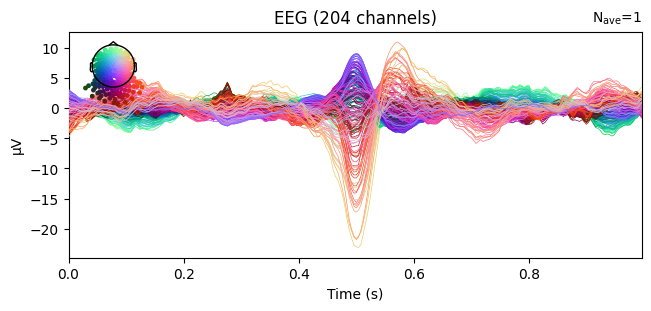

In [37]:
_ = eeg.plot()

⚙️ <font color=green>**Select time points to reconstruct**</font>: CSET is an iterative process. This can be quite slow, so let's restrain the number of time points we reconstruct.

Number of time points: (204, 25)


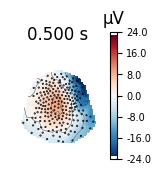

In [38]:
tmin  = 0.45
tmax  = 0.55
tviz  = 0.5
sfreq = eeg.info["sfreq"]

b = eeg.get_data("eeg", tmin=tmin, tmax=tmax)

print(f"Number of time points: {b.shape}")
_ = eeg.plot_topomap([tviz], outlines=None, extrapolate="local")

## Solve The Inverse Problem

⚙️ <font color=green>**Write the optimization problem**</font>: Using the `pyxu` package we can write down any optimization problem and then solve them.

In [39]:
# forward * connectome spectrum
A = fwd@cst.T

# Depth weighting
A_norms = np.linalg.norm(A, ord=2, axis=0)
A       = A/A_norms[None,:]

# data normalization
y_norms = np.linalg.norm(b, ord=2, axis=0)
y       = b/y_norms[None,:]

# initial guess
alpha0 = np.zeros(fwd.shape[1])

# operators
A       = pxa.LinOp.from_array(A)             
l1_norm = lam*pxo.L1Norm(dim_shape=alpha0.shape[0])

solution  = np.zeros((fwd.shape[1], b.shape[1]))
stop_crit = pxst.RelError(eps=1e-8, var="x", f=None, norm=2, satisfy_all=True)
for i in range(b.shape[1]):
    l22_loss = pxo.SquaredL2Norm(dim_shape=A.codim_shape[0]).argshift(-y[:,i]) * A
    l22_loss.diff_lipschitz = l22_loss.estimate_diff_lipschitz()

    solver = PGD(f=l22_loss, g=l1_norm, show_progress=False)

    solver.fit(x0=np.zeros(l22_loss.dim_shape), acceleration=True, stop_crit=stop_crit)
    
    alpha    = solver.solution().squeeze()
    solution[:,i] = cst.T@alpha*y_norms[i]*A_norms

#### <font color=yellow>🌟</font> Visualize reconstruction

In [40]:
mm.viz.plot_brain_time_series(forward["src"], np.abs(solution), sfreq, cmap="reds")

Widget(value='<iframe src="http://localhost:45913/index.html?ui=P_0x7fbdf9783ec0_19&reconnect=auto" class="pyv…

## 💾 Save result

In [9]:
save = "mne"
#save = "bv"

fname  = f"{sub}_cset-{lam}"
folder = mm_dir/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving estimation of subject: {sub}")
if save == "mne":
    vertices = [forward["src"][0]["vertno"], forward["src"][1]["vertno"]]
    stc = mne.SourceEstimate(solution, vertices, tmin=0, tstep=1/sfreq, subject=sub)
    stc.save(folder/fname, overwrite=True)
    
if save == "bv":
    trans = mm.utils.compute_transformation(sub, fs_dir, "mri", "head", "m")
    mm.io.write_stc(
        fname  = fname,
        folder = folder,
        stc    = stc, 
        src    = forward["src"],
        trans  = trans, 
        overwrite = True, 
    )

Writing STC to disk...
[done]
